# Tutorial Notebook for IT_TF github repository

This notebook is WIP. Documentation will be added shortly. For now, we only go through regenerating the main figures in the paper

## Information Decay 
#### Starting from the ground up, we will generate 2 column MI/PI motifOrganisms encoding 1 bit of Total Information . We then bombard these motifs with mutations and compare how quickly their information decays. 

First, let's generate the motifPopulation with PI organisms. All scripts in this repo are setup to work with parameters specified through json files. As such, we specify the parameters for the population before running the script which generates the desired motif Population

##### Note: In any/all scripts, PI from the paper is referred to as IC in the code

In [1]:
import json

In [2]:
#Writing proper parameters for IC population to JSON file
ICjsonfile_fig1 = {
    "inputFile": None, #Loads in pre-generated motifPopulation or starts from scratch
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50, #Biases the mutation towards certain letters if not set to 0.50
	"Mutation_Rate": 0.01, #Expected rate of mutations per generation (mean of Poisson distribution)
	"MI_mode": 1, #Overlapping pairs (1) or non-overlapping pairs (2) for computing MI
	"ReadInFiles": None, #Paths to fasta files for initilaizing motifModels
	"Target_TI_Column": 0.5, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 1, #Proportion of Target_TI_Column * Length_BindingSites that should be IC/PI
	"ConstrictMode": "IC", #Parameter of the fitness function. Determines whether to solely select for PI/IC, MI, or both
	"Eucledian_Thres": 0.05, #Max distance allowed for any organism from goal information before stopping simulation
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_1/ICpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig1, f, indent = 3)



In [3]:
import src.fitMotifPopulation

version 0.1.8


In [4]:
#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 6
Generation num: 400
Number Organisms below threshold: 56
Generation num: 500
Number Organisms below threshold: 95
Generation num: 600


We then run the information decay experiment outlined in the paper, where we bombard our generated motifs with mutations in the absence of any selection pressure to see how fast the information decays

In [5]:
ICjsonfile_fig1_decay = {
    "Population_File":"./Notebook/Populations/Figure_1/ICpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv"	
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(ICjsonfile_fig1_decay, f, indent = 3)

In [6]:
import src.informationDecay

In [7]:
#We then run the Information Decay experiment
src.informationDecay.main()

Let's do the same with MI motifs. The only `parameters` changed are `Prop_IC` and `ConstrictMode`

In [8]:
#Writing proper parameters for MI population to JSON file
MIjsonfile_fig1 = {
    "inputFile": None,
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": 0,
	"ConstrictMode": "MI",
	"Eucledian_Thres": 0.05,
    "restartPopulation": None,
	"populationOutputFile": "./Notebook/Populations/Figure_1/MIpop_fig1.json"
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(MIjsonfile_fig1, f, indent = 3)


In [9]:
#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 1
Generation num: 400
Number Organisms below threshold: 9
Generation num: 500
Number Organisms below threshold: 52
Generation num: 600
Number Organisms below threshold: 84
Generation num: 700
Number Organisms below threshold: 96
Generation num: 800
Number Organisms below threshold: 98
Generation num: 900


In [10]:
MIjsonfile_fig1_decay = {
    "Population_File":"./Notebook/Populations/Figure_1/MIpop_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv"		
}

with open("./src/settings_informationDecay.json", "w") as f:
    json.dump(MIjsonfile_fig1_decay, f, indent = 3)

In [11]:
#We then run the Information Decay experiment
src.informationDecay.main()

Visualizing the results. In figureFunctions.py, all the graphs from the paper and supplementary document can be regenerated given the results have already been generated

In [12]:
import src.figureFunctions


Figure(640x480)


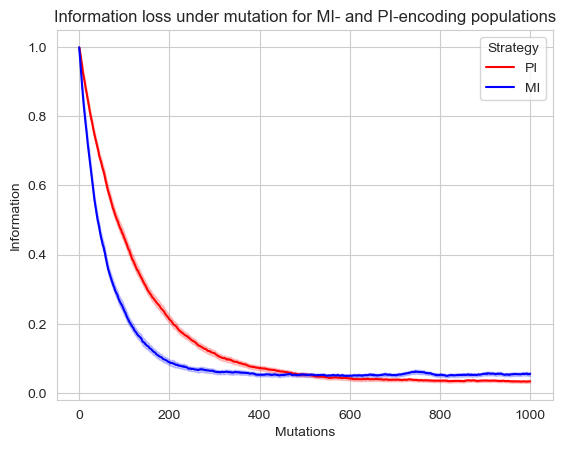

In [13]:
#Note: For the figure functions, order that we pass in the files is very important
print(src.figureFunctions.Figure1(["./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv",
                                   "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv"])) #Figure1

##### The above figure seems to indicate PI motifs maintain more of their Information after mutation than MI motifs. What about motifs between 100% IC and 100% MI? We proceed to generate motifs that encode their Information somewhere between 100% IC and 100% MI and compare their mutational resillience 

In [14]:
#Defines encoding strategies. 0% IC 100% MI, 25% IC 75% MI, ...
propInformation = [0,0.25,0.50, 0.75,1]

#Repeats the process completed above for each strata between 100% IC and 100% MI in propInformation
for percentageIC in propInformation:

    #Generates json file and outputs it
    mixedjsonfile_fig1 = {
    "inputFile": None,
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 2,
	"GC_cont": 0.50,
	"Mutation_Rate": 0.01,
	"MI_mode": 1,
	"ReadInFiles": None,
	"Target_TI_Column": 0.5,
	"Prop_IC": percentageIC,
	"ConstrictMode": "",
	"Eucledian_Thres": 0.05,
    "restartPopulation": None,
	"populationOutputFile": f"./Notebook/Populations/SuppFigure_1/mixedpop_{percentageIC}_fig1.json"
    
    }  
    with open("./src/settings_fitMotifPop.json", "w") as f:
        json.dump(mixedjsonfile_fig1, f, indent = 3)

    #Generates population
    src.fitMotifPopulation.main() 

    #Runs information decay experiment
    mixedjsonfile_fig1_decay = {
    "Population_File":f"./Notebook/Populations/SuppFigure_1/mixedpop_{percentageIC}_fig1.json",
	"NumGenerationTerminate":1000,
	"lossOutputCSV": f"./Notebook/Results/SuppFigure_1/informationDecay_mixedpop_{percentageIC}_fig1.csv"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(mixedjsonfile_fig1_decay, f, indent = 3)

    print(f"Done with {percentageIC}IC motifPopulation!") 
        
    src.informationDecay.main()

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 13
Generation num: 500
Number Organisms below threshold: 37
Generation num: 600
Number Organisms below threshold: 69
Generation num: 700
Number Organisms below threshold: 89
Generation num: 800
Number Organisms below threshold: 96
Generation num: 900
Number Organisms below threshold: 99
Generation num: 1000
Number Organisms below threshold: 99
Generation num: 1100
Done with 0IC motifPopulation!
Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 1
Generation num: 400
Number Organisms below threshold: 14
Generation num: 500
Number Organisms below threshold: 39
Generation num: 600
Number

Figure(640x480)


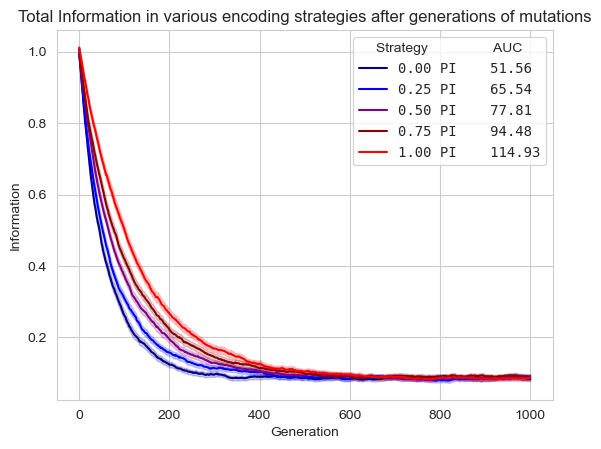

In [15]:
#Visualizing the results!
print(src.figureFunctions.SupplementaryFigure1([f"./Notebook/Results/SuppFigure_1/informationDecay_mixedpop_{percentageIC}_fig1.csv" for percentageIC in propInformation]))

##### The above figure seems to suggest that motifs that encode most of their information through PI are better positioned to maintain Information than motifs that trend more towards MI. We can see a clear improvement in mutational resilience going from MI to PI. 

##### A follow-up question. Transcription factors (TF) bind to sites that follow a certain motif pattern. Problems arise when these binding sites get mutated and start diverging from the pattern recognized by the TF. We can represent the original pattern as a probability frequency distribution and the mutated sites as another distribution. How does the divergence of IC binding sites from the motif after mutations compared to MI binding sites? To measure divergence, we employ Jennsen-Shannon Divergence

Figure(640x480)


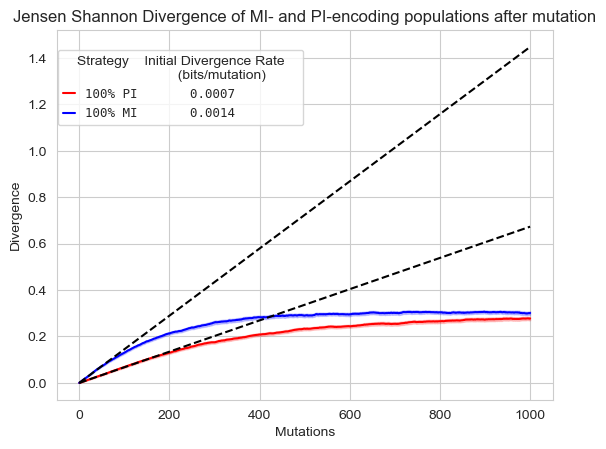

In [16]:
#Reusing the IC/MI informationDecay files we already generated, the JSD figure is visualized below
print(src.figureFunctions.SupplementaryFigure2(["./Notebook/Results/Figure_1/informationDecay_ICpop_fig1.csv", 
                                   "./Notebook/Results/Figure_1/informationDecay_MIpop_fig1.csv"]))

##### Examining whether these mutational resillience properties remain true of IC and MI motifs as we vary Information Density by altering `Target_TI_Column`

You could generate the populations yourself by setting `Target_TI_Column` to the following values: 0.25, 0.5, 0.75, and 1 bit for `Prop_IC` = 1 and `ConstrictMode` = IC as well for `Prop_IC`=0 and `ConstrictMode` = MI. This has already been done for you and saved to the repo. Here, we simply load in the pre-generated population 

In [17]:
#Defines different TI values for 2bp motif. 
TIlist = [0.5,1,1.5,2] 

#Repeats for MI and IC
for strategy in ["IC","MI"]:
    
    #Repeats the process completed above for each information density value in the list above
    for TI in TIlist:
        
        #Runs information decay experiment
        jsonfile_fig2_decay = {
        "Population_File":f"./Notebook/Populations/Figure_2/motifPop_{TI}bit{strategy}_2col.json",
    	"NumGenerationTerminate":1000,
    	"lossOutputCSV": f"./Notebook/Results/Figure_2/informationDecay_{TI}bit{strategy}.csv"	
        }
    
        with open("./src/settings_informationDecay.json", "w") as f:
            json.dump(jsonfile_fig2_decay, f, indent = 3)
                
        src.informationDecay.main()
    
    print(f"Done with {strategy} motifPopulations!") 


Done with IC motifPopulations!
Done with MI motifPopulations!


Figure(640x480)


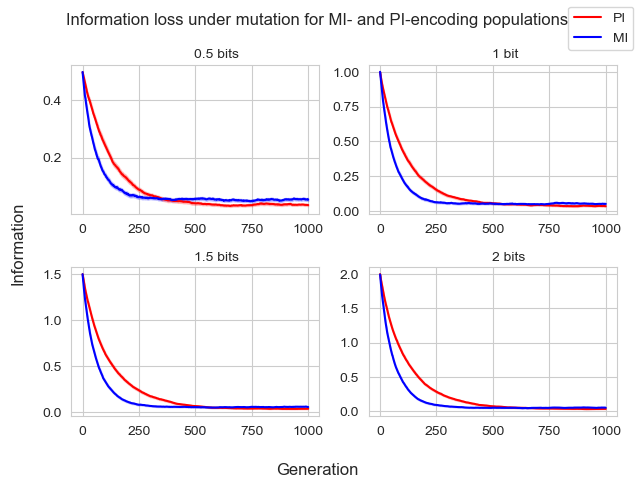

In [18]:
fig2_fileList = []
for TI in TIlist:
    fig2_fileList.append([f"./Notebook/Results/Figure_2/informationDecay_{TI}bitIC.csv",
                          f"./Notebook/Results/Figure_2/informationDecay_{TI}bitMI.csv" ])
fig2_fileList
print(src.figureFunctions.Figure2(fig2_fileList))

##### Finally, we generate more realistically sized motifs and repeat the information decay experiments 

You can generate these PI/MI MotifPopulations with `target_TI_Column`: 0.5 and `Length_BindingSites` = 12 selecting for PI/MI by altering `Prop_IC` to 1/0 and `ConstrictMode` to IC/MI. The generated populations are already saved and loaded in here:

In [19]:
#IC example (MI example takes much more time to generate)
ICjsonfile_fig3 = {
    "inputFile": None, 
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 12,
	"GC_cont": 0.50, 
	"Mutation_Rate": 0.01, 
	"MI_mode": 1, 
	"ReadInFiles": None, 
	"Target_TI_Column": 0.5, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 1, #Adjust this to 0 for the MI population
	"ConstrictMode": "IC", #Adjust this to MI for the MI population
	"Eucledian_Thres": 0.05, 
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_3/motifPop_6bitIC_12col.json" #Adjust this to not overwrite for MI population
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig3, f, indent = 3)

#We then generate the ICmotifPop
src.fitMotifPopulation.main() 


Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 0
Generation num: 500
Number Organisms below threshold: 0
Generation num: 600
Number Organisms below threshold: 0
Generation num: 700
Number Organisms below threshold: 0
Generation num: 800
Number Organisms below threshold: 0
Generation num: 900
Number Organisms below threshold: 0
Generation num: 1000
Number Organisms below threshold: 0
Generation num: 1100
Number Organisms below threshold: 0
Generation num: 1200
Number Organisms below threshold: 0
Generation num: 1300
Number Organisms below threshold: 0
Generation num: 1400
Number Organisms below threshold: 0
Generation num: 1500
Number Organisms below threshold: 0
Generation num: 1600
Number Organisms below threshold: 0
Generation num: 1700
Number Organisms below threshold: 0
Gene

In [22]:
for strategy in ["IC", "MI"]:
    jsonfile_fig3_decay = {
        "Population_File":f"./Notebook/Populations/Figure_3/motifPop_6bit{strategy}_12col.json",
    	"NumGenerationTerminate":5000,
    	"lossOutputCSV": f"./Notebook/Results/Figure_3/informationDecay_{strategy}bit.csv"	
    }

    with open("./src/settings_informationDecay.json", "w") as f:
        json.dump(jsonfile_fig3_decay, f, indent = 3)
    
    #We then run the Information Decay experiment
    src.informationDecay.main()

Figure(640x480)


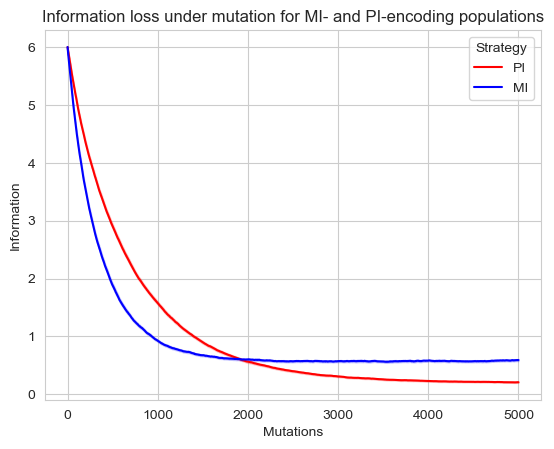

In [23]:
print(src.figureFunctions.Figure3(["./Notebook/Results/Figure_3/informationDecay_ICbit.csv", "./Notebook/Results/Figure_3/informationDecay_MIbit.csv"])) 

In [24]:
#IC example (MI example takes much more time to generate)
ICjsonfile_fig1 = {
    "inputFile": None, 
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 6,
	"GC_cont": 0.50, 
	"Mutation_Rate": 0.01, 
	"MI_mode": 1, 
	"ReadInFiles": None, 
	"Target_TI_Column": 0.5, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 1, #Adjust this to 0 for the MI population
	"ConstrictMode": "IC", #Adjust this to MI for the MI population
	"Eucledian_Thres": 0.05, 
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_3/motifPop_3bitIC_6col.json" #Adjust this to not overwrite for MI population
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig1, f, indent = 3)

#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 0
Generation num: 500
Number Organisms below threshold: 0
Generation num: 600
Number Organisms below threshold: 0
Generation num: 700
Number Organisms below threshold: 0
Generation num: 800
Number Organisms below threshold: 0
Generation num: 900
Number Organisms below threshold: 0
Generation num: 1000
Number Organisms below threshold: 0
Generation num: 1100
Number Organisms below threshold: 0
Generation num: 1200
Number Organisms below threshold: 0
Generation num: 1300
Number Organisms below threshold: 0
Generation num: 1400
Number Organisms below threshold: 1
Generation num: 1500
Number Organisms below threshold: 4
Generation num: 1600
Number Organisms below threshold: 11
Generation num: 1700
Number Organisms below threshold: 23
Ge

In [ ]:
#IC example (MI example takes much more time to generate)
ICjsonfile_fig1 = {
    "inputFile": None, 
	"Number_Organisms": 100,
	"Number_BindingSites": 128,
	"Length_BindingSites": 6,
	"GC_cont": 0.50, 
	"Mutation_Rate": 0.01, 
	"MI_mode": 1, 
	"ReadInFiles": None, 
	"Target_TI_Column": 0.5, #Target_TI_Column * Length_BindingSites equals desired bits of information
	"Prop_IC": 0, #Adjust this to 0 for the MI population
	"ConstrictMode": "MI", #Adjust this to MI for the MI population
	"Eucledian_Thres": 0.05, 
    "restartPopulation": None, #If int specified, restarts population after # of generations. May help if getting stuck in local optima
	"populationOutputFile": "./Notebook/Populations/Figure_3/motifPop_3bitMI_6col.json" #Adjust this to not overwrite for MI population
}  

with open("./src/settings_fitMotifPop.json", "w") as f:
    json.dump(ICjsonfile_fig1, f, indent = 3)

#We then generate the ICmotifPop
src.fitMotifPopulation.main() 

Number Organisms below threshold: 0
Generation num: 100
Number Organisms below threshold: 0
Generation num: 200
Number Organisms below threshold: 0
Generation num: 300
Number Organisms below threshold: 0
Generation num: 400
Number Organisms below threshold: 0
Generation num: 500
Number Organisms below threshold: 0
Generation num: 600
Number Organisms below threshold: 0
Generation num: 700
Number Organisms below threshold: 0
Generation num: 800
Number Organisms below threshold: 0
Generation num: 900
Number Organisms below threshold: 0
Generation num: 1000
Number Organisms below threshold: 0
Generation num: 1100
Number Organisms below threshold: 0
Generation num: 1200
Number Organisms below threshold: 0
Generation num: 1300
Number Organisms below threshold: 0
Generation num: 1400
Number Organisms below threshold: 0
Generation num: 1500
Number Organisms below threshold: 0
Generation num: 1600
Number Organisms below threshold: 0
Generation num: 1700
Number Organisms below threshold: 0
Gene

# Genome Search
We now further complicate our model by introducing a genome to explore interesting properties about PI/MI motifs. Specifically, we insert our motifs into a genome, introduce mutations to the genome, and measure how quickly the classification ability of binding sites from non-binding sites degrade. We measure classification ability through AUPRC and train a Kulakovsky model on the binding sites before mutation to classify binding sites and non-binding sites.  

First, we load in our 6bp length fitted motifs. We apply the reduce residual information script so that both the PI and MI populations have the same amount of total information (if we did not do this, the AUPRC of both curves below would not start at the exact same place). We then run the genome search experiment by embedding the loaded motifs in randomly generated sequences (Code for doing so commented below. Too time-intensive to run in a notebook). We then measure AUPRC after mutation.


In [22]:
import src.genomeSearch
import src.main_removeResidual

Balance for residual information. This script accepts two populations and reduces the residual MI of the PI population s.t. both populations have equal Total Information. 


In [23]:
jsonfile_equalizeResidual = {
    "populationList":["./Notebook/Populations/Figure_3/motifPop_6bitMI_12col.json", "./Notebook/Populations/Figure_3/motifPop_6bitIC_12col.json"], #Input population paths. Order sensitive.  
    "MSE_thres":0.01
}

with open("./src/settings_residual.json", "w") as f:
    json.dump(jsonfile_equalizeResidual, f, indent = 3)

#Equalizes residual information and saves to same path
src.main_removeResidual.main()

0.18443922146410668
0.002934315510949911


Note: This will take a *long* time if run in a jupyter notebook. As such, the results have already been generated by running the script and have been saved to Notebook/Results/Figure_4

In [24]:
run_code = False

if run_code:
    #Repeats for MI and IC
    for strategy in ["IC","MI"]:
        propIC = 1 if strategy == "IC" else 0
        #Repeats the process completed above for each motifLength above
        for L in motifLengths:
            inputMotifFilePath = f"./Notebook/Populations/Figure_3/motifPop_6bit{strategy}_12col.json"
            
            jsonfile_mainfig = {
            	"Population_File": inputMotifFilePath,
                "genomeLength": 8192, #Appropriate genome length according to Schneider's equation given 6 bits of information and 128 binding sites
                "NumGenerationTerminate": 10000, #Done in paper
                "lossOutputCSV": f"/Notebook/Results/Figure_4/genomeSearch_6bit{strategy}_12col.csv"
            }  
    
            with open("./src/settings_GenomeExperiment.json", "w") as f:
                json.dump(jsonfile_mainfig, f, indent = 3)
    
            #Runs genomeSearch
            src.genomeSearch.main() 


Figure(640x480)


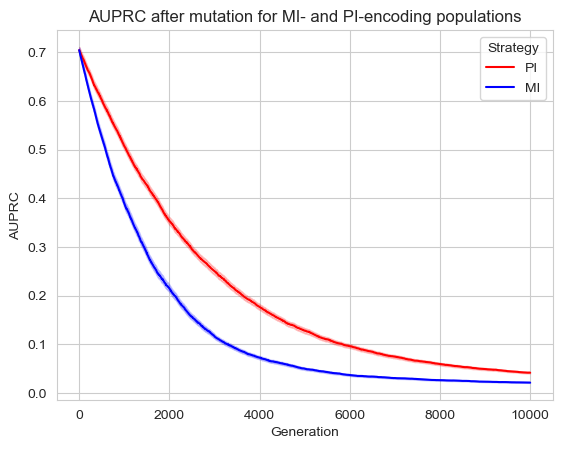

In [25]:
print(src.figureFunctions.Figure4solo(["./Notebook/Results/Figure_4/genomeSearch_6bitIC_12col.csv", "./Notebook/Results/Figure_4/genomeSearch_6bitMI_12col.csv"]))

# Coevolutionary Simulation
To further explore fitness properties of PI/MI TRNs, we use a coevolutionary simulation to evolve recognizers/binding sites along with the rest of the genome. We first tackle the question of whether MI or PI TRNs would propagate in a population as a property of the mutational resillience of PI TRNs (competition experiment). Given this mutational robustness property, we next ask whether TRNs would naturally move towards encoding their information through PI while solely selecting for classification performance (vector field). Please note that all of the below work was done with the assistance of a high performance computing cluster; however, the generated results are saved in the repo

Here, we demonstrate how the coevolutionary simulation functions by presenting the code necessary to generate the organisms for the competition experiment. To generate the PI vs MI organisms, we have to change `Percent_MI` parameter to 0.70 for MI organisms and 0.30 for PI organisms.

In [26]:
run_code = False

if run_code:
    #Repeats for MI and IC
    for strategy in ["IC","MI"]:
        propMI = 0.30 if strategy == "IC" else 0.70
        
        #More documentation available in script
        jsonfile_mainfig = {
            "Input_Files": None, #Input Files to seed coevolutionary simulation. Null starts from random
            "Number_Organisms": 2000,
            "Percent_MI": propMI, #What percentage MI to select for. percentage IC = 1 - percentageMI
            "Alpha": 1, #Weighting of Percent_MI in fitness function. Set to 0 to not consider percent_MI/IC at all
            "AUPRC":1, #What AUPRC to fit towards
            "Beta": 100, #Base of exponent in fitness population
            "Genome_Length": 2048,
            "Number_BindingSites_Recognizer": 32,
            "Length_BindingSites": 6,
            "Number_BindingSites": 32,
            "Stopping_Criteria": None, #Stopping criteria. Set to null to stop when top organism is at 1AUPRC 
            "Error_Threshold": 0.02, #Only relevent when Stopping_criteria = fitness. Used in preparing vector field experiment
            "Grid_Threshold": 0.10, #Only relevent when Stopping_criteria = grid. Used in conducting vector field experiment
            "idList": None, #Only relevent when running the competition experiment
            "run_mode":"parallel", 
            "Output_Folder":f"/Users/Emmanuel/Documents/Research Projects/ITTF/Output/Generate{strategy}Orgs/", #Saves below files to this path
            "Output_CSV_FileName": f"runCompetition.csv", #Outputs statistics of simulation
            "Output_Diversity_FileName":"diversity.csv",
            "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json", #Outputs top AUPRC organism
            "Output_topFitness_Org_FileName": "MIorg_topFitness.json", #Outputs top fitness organism
            "Output_Pop_FileName": "MIpop.json" #Outputs population file
            }  
    
        with open("./src/settings_fitCoevPop.json", "w") as f:
            json.dump(jsonfile_mainfig, f, indent = 3)
    
        #Generates organism
        src.fitCoevPopulation.main() 


Note, for the competition experiment, we generated 25 PI and MI organisms using the above code in a high performance computing cluster. We then generated 100 pairings with replacement (saved in `Output/competitionPairs/`). The code below demonstrates what would need to be done to run the competition experiment (we would need to repeat this process for all 100 pairs). Results are saved in `Output/resultsCompetition`. 

To run the competition experiment, we have to change `Input_Files` to start the simulation from our pre-generated organisms, `Alpha` since we are no longer selecting for %MI/PI, `Stopping_Criteria` as we stop the simulation when all organisms in the population come from one parent organism, and `idList` to give each parent organism an id (i.e. MI_70 for the MI organism)

In [27]:
run_mode = False

if run_mode:
    #More documentation available in script
    jsonfile_mainfig = {
        "Input_Files": ["./Output/competitionPairs/competitionpair_0/MIorg.json","./Output/competitionPairs/competitionpair_0/ICorg.json"], #Initializes population by duplicating the organisms stored in these two file paths 
        "Number_Organisms": 2000,
        "Percent_MI": 0.30, 
        "Alpha": 0, #Solely selects for AUPRC
        "AUPRC":1, 
        "Beta": 100, 
        "Genome_Length": 2048,
        "Number_BindingSites_Recognizer": 32,
        "Length_BindingSites": 6,
        "Number_BindingSites": 32,
        "Stopping_Criteria": "competition", #Stops when one organism out-competes the other (when all organisms in the population come from one of the two above organisms)
        "Error_Threshold": 0.02, #Only relevent when Stopping_criteria = fitness. Used in preparing vector field experiment
        "Grid_Threshold": 0.10, #Only relevent when Stopping_criteria = grid. Used in conducting vector field experiment
        "idList": ["MI_70","MI_30"], #ID tags of two parent organisms. 
        "run_mode":"parallel", 
        "Output_Folder":f"/Users/Emmanuel/Documents/Research Projects/ITTF/Output/resultsCompetition/competitionpair_0/", #Saves below files to this path
        "Output_CSV_FileName": f"/Users/Emmanuel/Documents/Research Projects/ITTF/Output/resultsCompetition/competitionpair_0/runCompetition.csv", #Saves to absolute path
        "Output_Diversity_FileName":"diversity.csv",
        "Output_topAUPRC_Org_FileName": "MIorg_topAUPRC.json", #Outputs top AUPRC organism
        "Output_topFitness_Org_FileName": "MIorg_topFitness.json", #Outputs top fitness organism
        "Output_Pop_FileName": "MIpop.json" #Outputs population file
        }  
    
    with open("./src/settings_fitCoevPop.json", "w") as f:
        json.dump(jsonfile_mainfig, f, indent = 3)
    
    #Generates organism
    src.fitCoevPopulation.main() 


      Generation  MI_70 org frequency  MI_30 org frequency
0              0               0.5000               0.5000
1              1               0.4915               0.5085
2              2               0.4780               0.5220
3              3               0.4780               0.5220
4              4               0.4780               0.5220
...          ...                  ...                  ...
1495         280               0.0000               1.0000
1496         280               0.0000               1.0000
1497         280               0.0000               1.0000
1498         280               0.0000               1.0000
1499         280               0.0000               1.0000

[1500 rows x 3 columns]
Figure(640x480)


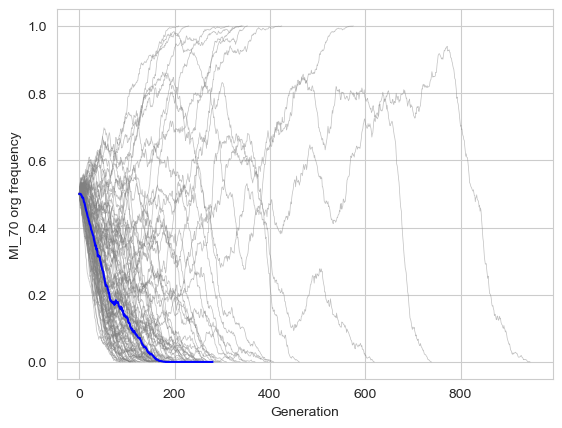

In [28]:
#Plots figure from saved results
print(src.figureFunctions.competitionFig())